**Comparison of Romer's hybrid multifactor scheme with the quadratic hybrid scheme**

In [ ]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from black import black_otm_impvol_mc
from qrheston import QuadraticRoughHeston
from qrheston_approx import simulate_qrh_approx
from fwd_var_curve import xi_curve_smooth
from utils import var_swap_robust, y0_from_xi0
from _calib_params import get_calibration_params, CALIB_DATES
from scipy.special import roots_jacobi

sns.set_theme(context="talk", style="ticks", font_scale=1.2)
mpl.rcParams["figure.figsize"] = (8, 6)
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
SEED = 1234

In [2]:
# pick a date
date = CALIB_DATES[0]
print(date)

20241219


In [3]:
# load SPX and VIX data
df_spx = pd.read_csv(f"data/{date}_spx_vol.csv")
df_vix = pd.read_csv(f"data/{date}_vix_vol.csv")

In [4]:
# get xi_0 curve from SPX var swaps
res_vs = var_swap_robust(df_spx)
w_in = res_vs["vs_mid"] * res_vs["expiries"]
xi_smooth = xi_curve_smooth(res_vs["expiries"], w_in, eps=0.05)["xi_curve"]

/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


In [5]:
vix_expiries = df_vix["Texp"].unique()
print(vix_expiries * 250)  # maturity in days

[  3.   7.  12.  17.  21.  40.  59.  80. 104. 123. 141. 166.]


In [6]:
# define QRH instance with associated parameters
n_quad = 40
params = get_calibration_params(date)
qrh = QuadraticRoughHeston(**params, xi0=xi_smooth, n_quad=n_quad)

In [7]:
# simulation parameters
paths = 3 * 10**5
steps = 300
Ts = vix_expiries[:4]

### Hybrid scheme

In [8]:
qrh_mc = qrh.simulate(paths=paths, steps=steps, spx_expiries=Ts, seed=SEED)["spx"]

Simulating SPX expiries...
expiry: 0.0120
expiry: 0.0280
expiry: 0.0480
expiry: 0.0680


In [9]:
impvols_hybrid = {}

for T in Ts:
    S_mc = np.exp(qrh_mc[T]["X"])
    F_T = df_spx["Fwd"][df_spx["Texp"] == T].iloc[0]
    ks = np.log(df_spx["Strike"][df_spx["Texp"] == T] / F_T)
    impvol_qrh = black_otm_impvol_mc(S=np.exp(qrh_mc[T]["X"]), k=ks, T=T)
    impvols_hybrid[T] = {"ks": ks, "impvol": impvol_qrh}

/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value


### Romer's multifactor scheme 

In [10]:
# mapping Romer's parameters to the QRH framework
x_jac, w_jac = roots_jacobi(n=n_quad, alpha=2.0 * qrh.H - 1.0, beta=0.0)
params_romer = {
    "a0": lambda t: params["c"] * np.ones_like(t),
    "a1": lambda t: params["nu"] ** 2 * np.ones_like(t),
    "a2": lambda t: y0_from_xi0(t, xi_smooth, w_jac, x_jac, params) / params["nu"],
    "x0": lambda t: np.zeros_like(t),
    "b0": lambda t: np.zeros_like(t),
    "p": 1.0,
    "rho": 1.0,
    "H": qrh.H,
    "lam": params["lam"],
}

# kernel approximation parameters
eps_kernel = 1e-12
N_kernel = 1000

In [11]:
# Monte Carlo simulation of Romer's method

impvols_romer = {}
for T in Ts:
    print(f"Simulating T={T}...")
    _impvol = simulate_qrh_approx(
        params=params_romer,
        k=impvols_hybrid[T]["ks"],
        T=T,
        n_steps=steps,
        n_mc=paths,
        seed=SEED,
        eps_kernel=eps_kernel,
        N_kernel=N_kernel,
        endpoints_kernel=(None, None),
    )
    impvols_romer[T] = {"ks": impvols_hybrid[T]["ks"], "impvol": _impvol}

Simulating T=0.012...
Using N=20 exponentials for kernel approximation.
Simulating T=0.028...
Using N=20 exponentials for kernel approximation.
Simulating T=0.048...
Using N=20 exponentials for kernel approximation.
Simulating T=0.068...
Using N=20 exponentials for kernel approximation.


### Comparing both schemes

Absolute error for T=0.012: 77.10876622203156
Absolute error for T=0.028: 50.84365064303709
Absolute error for T=0.048: 80.40956214160371
Absolute error for T=0.068: 81.41826207629626


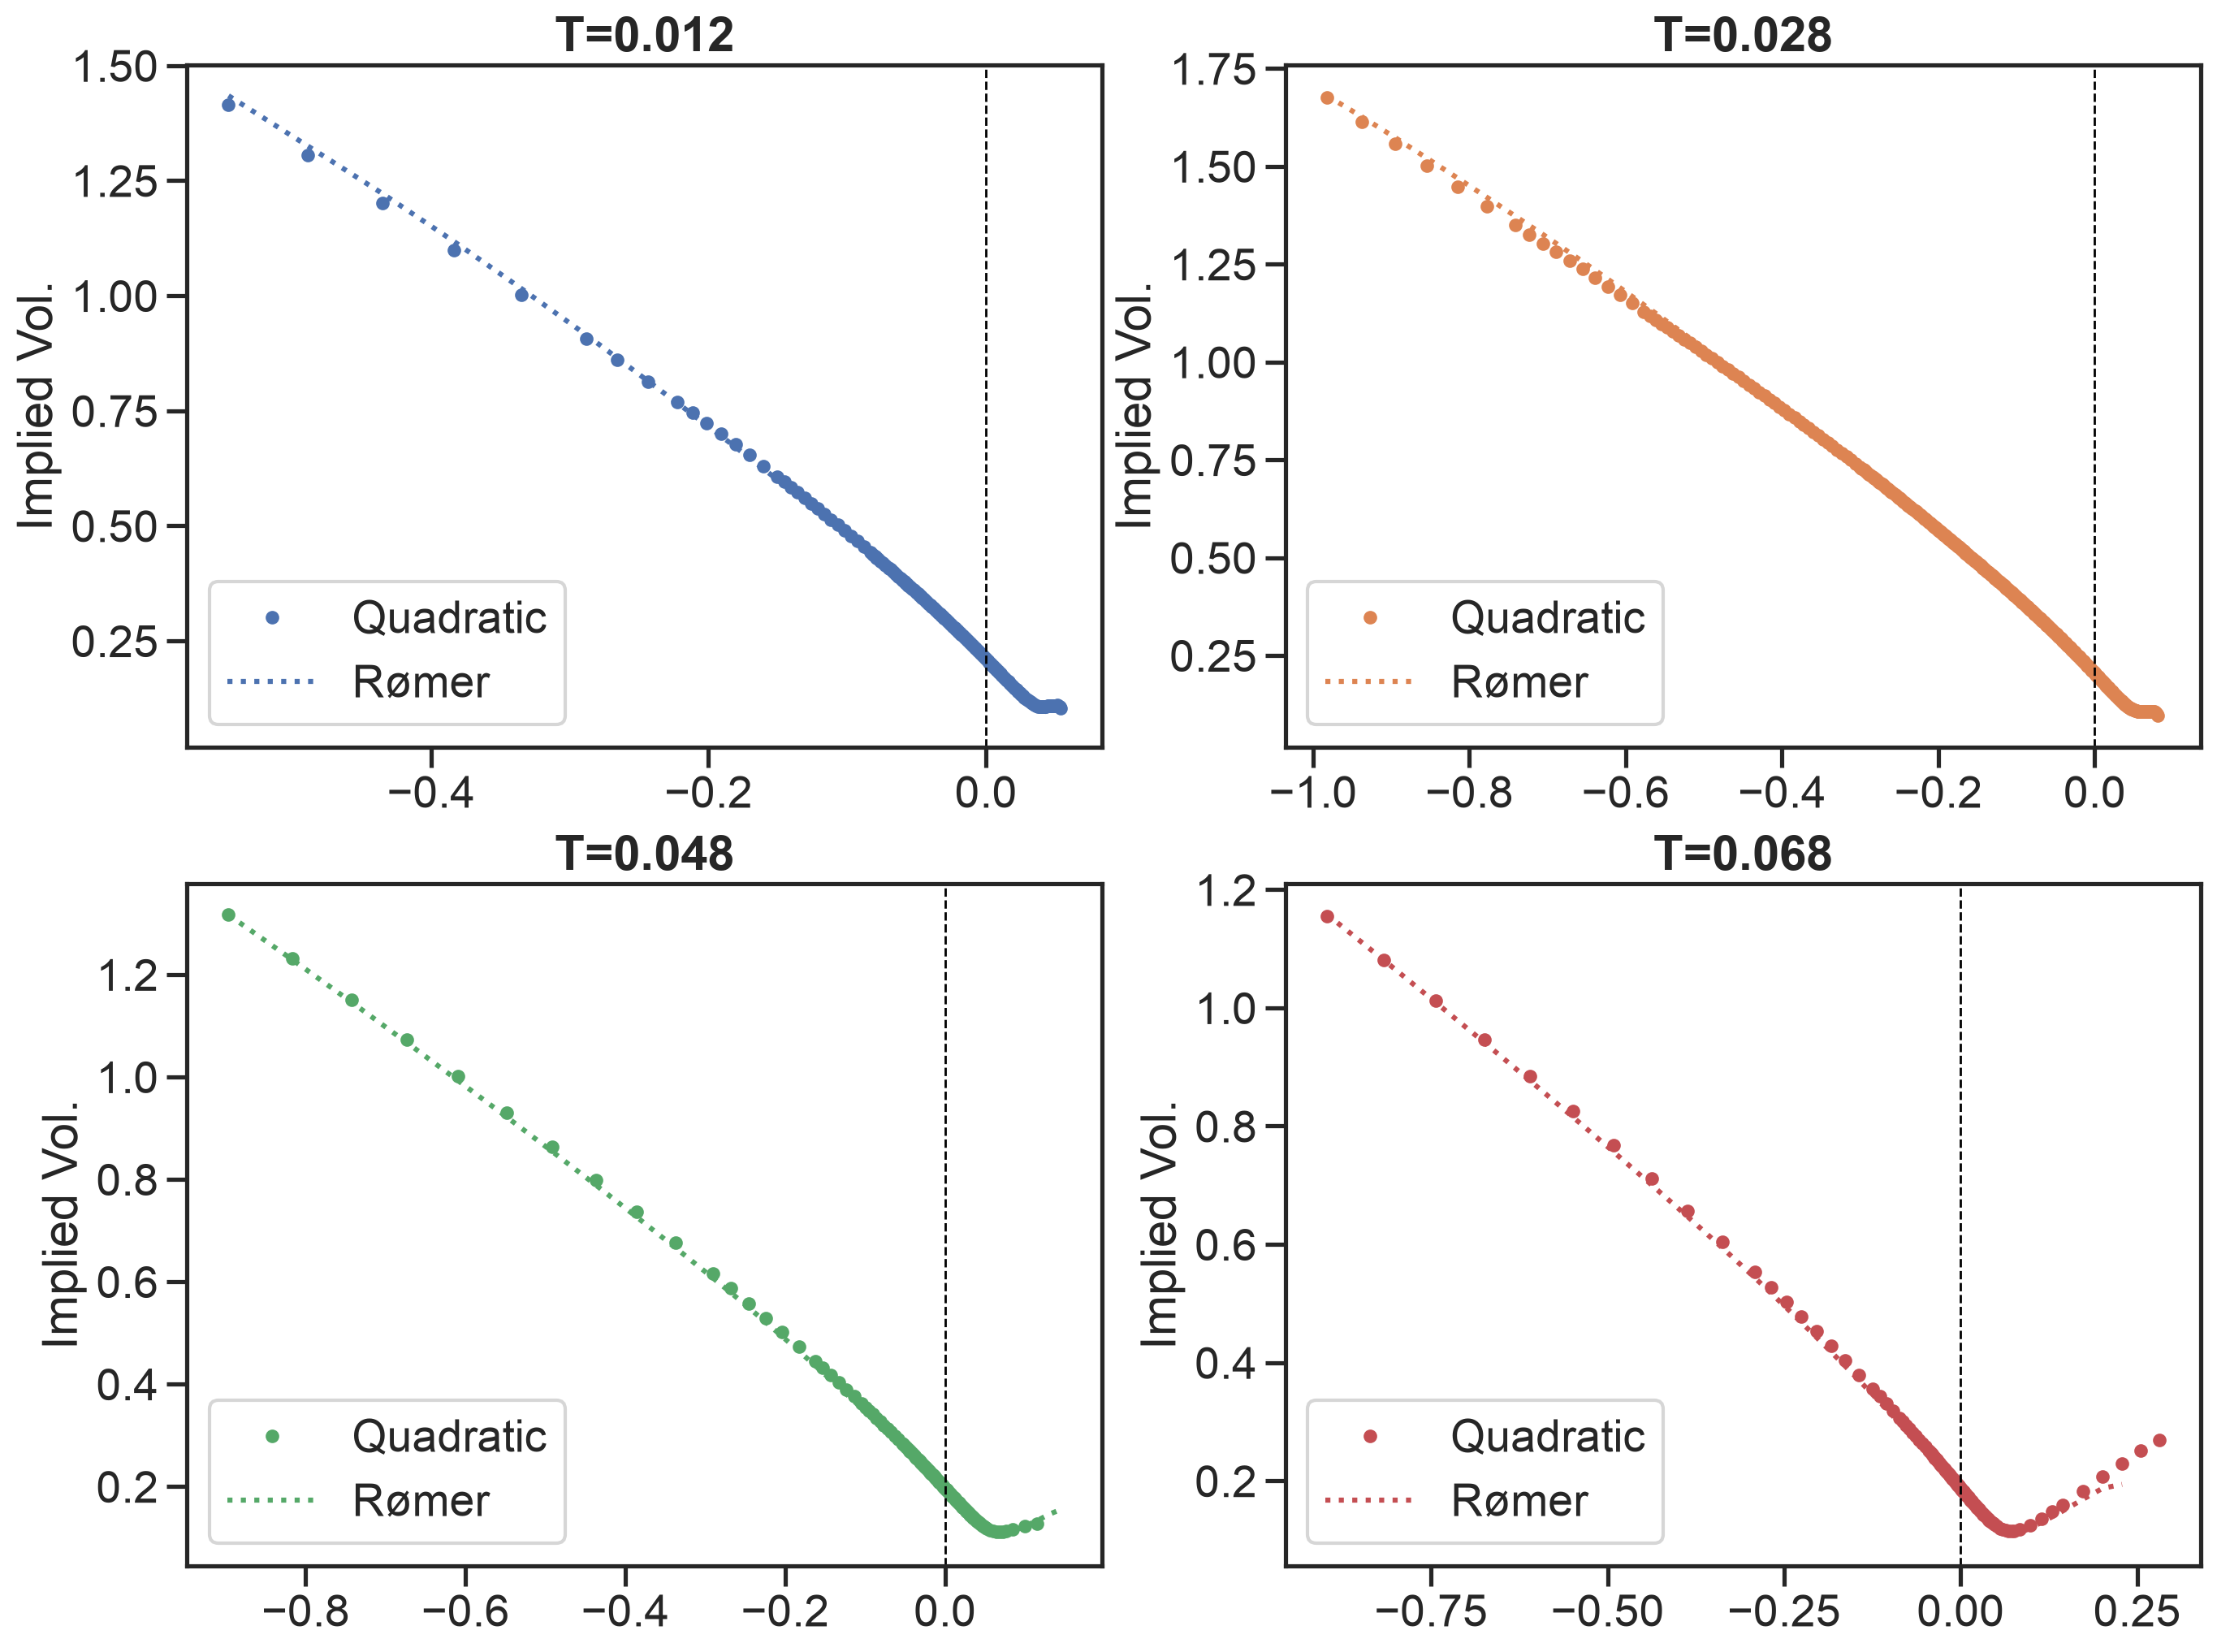

In [12]:
# comparison of Romer's scheme vs. QR scheme from the QRH paper
fig, axes = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))

for i, T in enumerate(Ts[:]):
    ks = impvols_hybrid[T]["ks"].to_numpy()
    left_lim = -np.inf
    if i == 0:
        left_lim = -0.6
    elif i == 1:
        left_lim = -1.0
    idx = ks > left_lim
    ks = ks[idx]
    impvol_qrh = impvols_hybrid[T]["impvol"][idx]
    impvol_romer = impvols_romer[T]["impvol"][idx]

    # Absolute error
    diff = impvol_qrh - impvol_romer
    abs_error = 1e4 * np.abs(diff[~np.isnan(diff)])
    print(f"Absolute error for T={T}: {np.median(abs_error)}")

    ax = axes.flat[i]
    ax.plot(
        ks,
        np.asarray(impvol_qrh),
        ".",
        markersize=10,
        color=COLORS[i],
        label="Quadratic",
    )
    ax.plot(
        ks,
        np.asarray(impvol_romer),
        ":",
        color=COLORS[i],
        markersize=10,
        label="Rømer",
    )

    ax.set_title(f"T={T}", fontweight="bold")
    ax.axvline(0, color="black", linestyle="--", lw=1)
    ax.set_ylabel("Implied Vol.")
    ax.legend()
plt.show()

# Convergence - timesteps 

We plot QRH smiles for increasing number of timesteps.

In [15]:
# pick up a maturity
T = Ts[-1]
F_T = df_spx["Fwd"][df_spx["Texp"] == T].iloc[0]
ks = np.log(df_spx["Strike"][df_spx["Texp"] == T] / F_T)

# MC paths
paths = 3 * 10**5

# list of timesteps to test
list_steps = [50, 100, 150, 200, 250, 300]

# store impvols
impvols_steps = {}

for step in list_steps:
    print(f"Simulating with {step} steps...")
    # QR scheme
    qrh_mc = qrh.simulate(paths=paths, steps=step, spx_expiries=[T], seed=SEED)["spx"]
    S_mc = np.exp(qrh_mc[T]["X"])
    impvols_steps[step] = black_otm_impvol_mc(S=np.exp(qrh_mc[T]["X"]), k=ks, T=T)
    print("\n")

Simulating with 50 steps...
Simulating SPX expiries...
expiry: 0.0680


/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value




Simulating with 100 steps...
Simulating SPX expiries...
expiry: 0.0680


Simulating with 150 steps...
Simulating SPX expiries...
expiry: 0.0680


Simulating with 200 steps...
Simulating SPX expiries...
expiry: 0.0680


Simulating with 250 steps...
Simulating SPX expiries...
expiry: 0.0680


Simulating with 300 steps...
Simulating SPX expiries...
expiry: 0.0680




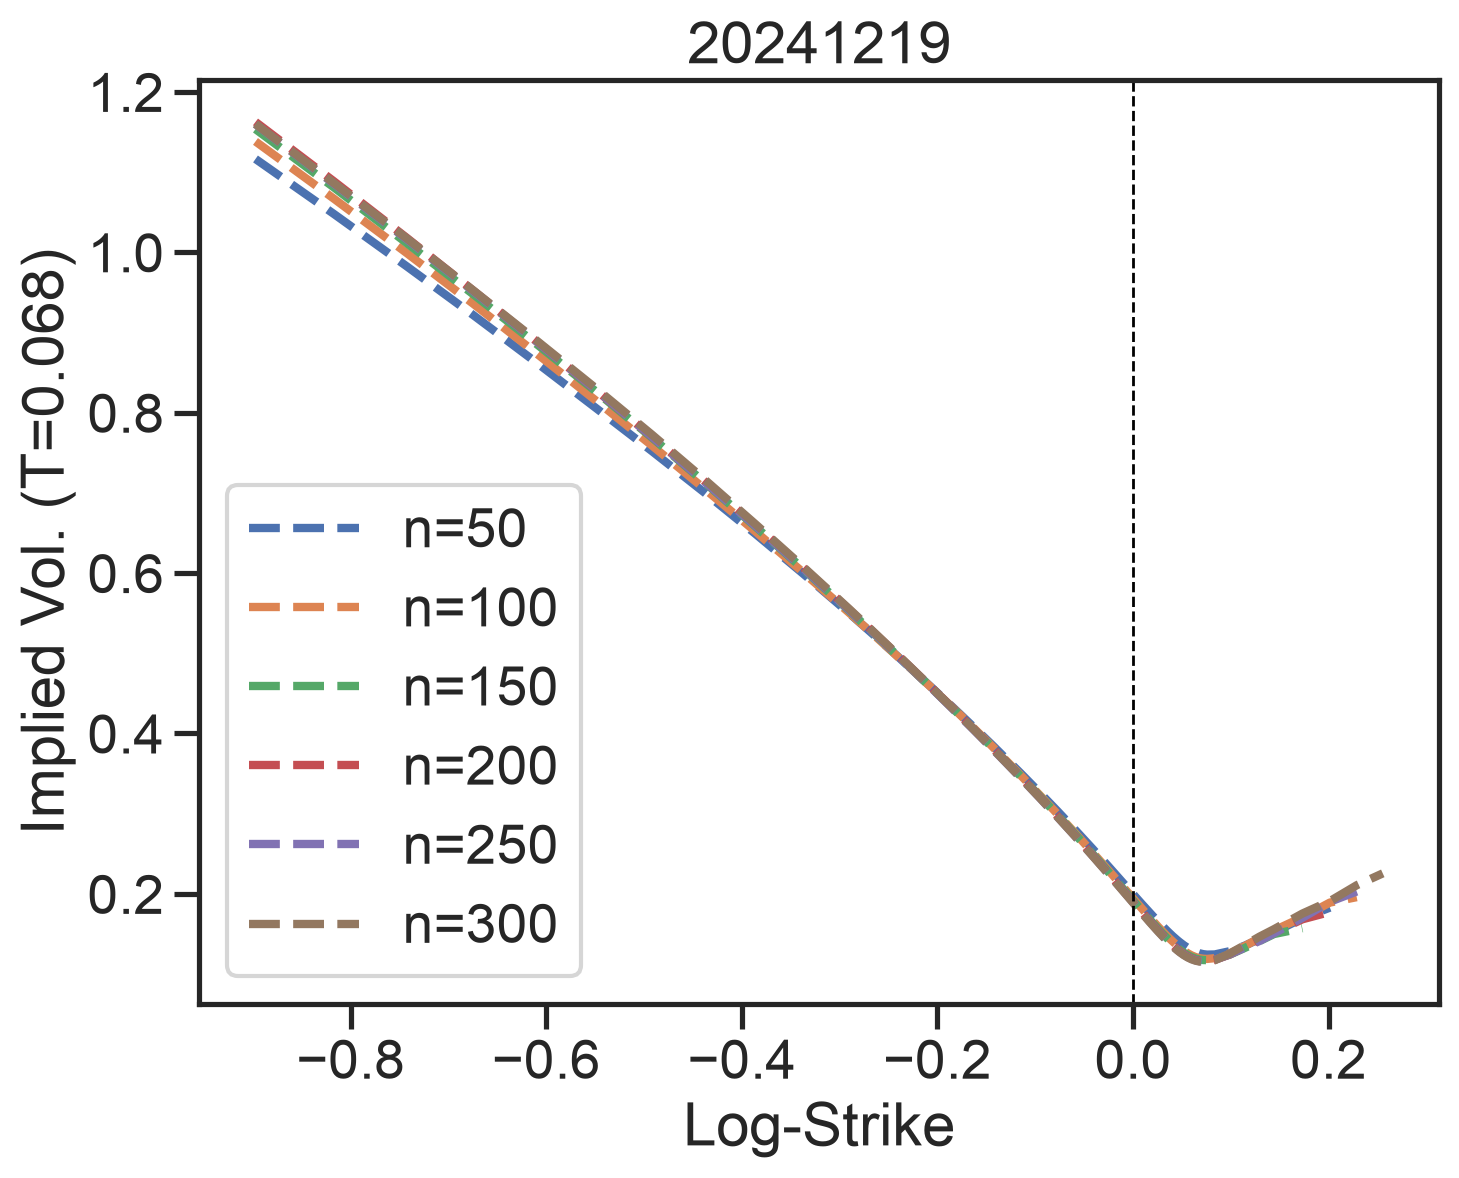

In [16]:
# Hybrid
fig, ax = plt.subplots()
for step in list_steps:
    ax.plot(ks, np.asarray(impvols_steps[step]), "--", lw=3, label=f"n={step}")
ax.axvline(0, color="black", linestyle="--", lw=1)
ax.set_xlabel("Log-Strike")
ax.set_ylabel(f"Implied Vol. (T={T:.3f})")
ax.set_title(f"{date}")
ax.legend()
plt.show()